<center><h1>Zhan_Jenna_HW7</h1></center>

Name:Jenna Zhan 
<br>
Github Username:jenna-zhan 
<br>
USC ID: 2477604908

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import hamming_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
mfccs = pd.read_csv("../data/Frogs_MFCCs.csv")

X = mfccs.iloc[:, :22]
y = mfccs[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state = 552
)

### (b) Train a classifier for each label

#### (i) Research


Exact match ratio: According to Sorower (2010), the exact match ratio measures the proportion of instances for which the predicted label set exactly matches the true label set.

$$
\text{exact match ratio}=\frac{1}{N}\sum_{i=1}^{N}I(Y_i=\hat{Y}_i)
$$

where $N$ is the number of instances, $Y_i$ is the true label set, $\hat{Y}_i$ is the predicted label set, and $I(\cdot)$ is the indicator function. This metric is strict because partially correct predictions are considered incorrect. A higher value indicates better performance.

Hamming loss: Sorower (2010) defines hamming loss as the average proportion of incorrectly assigned labels, including both missing and incorrectly predicted labels.

$$
\text{hamming loss}=\frac{1}{NL}\sum_{i=1}^{N}|Y_i\triangle\hat{Y}_i|
$$

where $L$ is the total number of possible labels and $\triangle$ denotes the symmetric difference between two label sets. A lower hamming loss indicates better performance, with 0 representing perfect predictions.

Hamming score: Following the definition used by Di Mauro et al. (2016), hamming score measures the proportion of correctly predicted binary label assignments.

$$
\text{hamming score}=\frac{1}{NL}\sum_{i=1}^{N}\sum_{j=1}^{L}I(y_{ij}=\hat{y}_{ij})
$$

Equivalently,

$$
\text{hamming score}=1-\text{hamming loss}
$$

A higher hamming score indicates better performance, with 1 representing perfect predictions.

For this dataset, the three categorical outputs (Family, Genus, and Species) contain 4, 8, and 10 classes, respectively. To apply the binary-label definitions above, the outputs can be represented using 22 binary indicators.

References:

Sorower, M. S. (2010). A Literature Survey on Algorithms for Multi-label Learning. Oregon State University.

Di Mauro, N., Vergari, A., & Esposito, F. (2016). Multi-Label Classification with Cutset Networks. https://www2.idsia.ch/cms/pgm/wp-content/uploads/sites/2/2016/07/DiMauro.pdf

#### (ii) Train a SVM for each of the labels

In [3]:
c_values = np.logspace(-3, 6, 10)
sigma_values = np.arange(0.1, 2.1, 0.1)
gamma_values = 1 / (2 * sigma_values**2)

In [4]:
screening_results = []

for C in c_values:
    for sigma, gamma in zip(sigma_values, gamma_values):
        model = OneVsRestClassifier(
            SVC(kernel = "rbf", C = C, gamma = gamma)
        )
        model.fit(X_train, y_train["Family"])

        accuracy = model.score(X_train, y_train["Family"])

        screening_results.append({
            "C": C,
            "sigma": sigma,
            "gamma": gamma,
            "training accuracy": accuracy
        })

screening_df = pd.DataFrame(screening_results)

In [5]:
valid_params = screening_df[screening_df["training accuracy"] >= 0.7]

print("total combinations:", len(screening_df))
print("valid combinations:", len(valid_params))
display(valid_params.head())

total combinations: 200
valid combinations: 177


,C,sigma,gamma,training accuracy
21,0.01,0.2,12.500000,0.771446
22,0.01,0.3,5.555556,0.922756
23,0.01,0.4,3.125000,0.938642
24,0.01,0.5,2.000000,0.936656
25,0.01,0.6,1.388889,0.916402


In [6]:
accuracy_table = screening_df.pivot(
    index = "C",
    columns = "sigma",
    values = "training accuracy"
)

display(accuracy_table.round(3))

sigma,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0
C,,,,,,,,,,,,,,,,,,,,
0.001,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613,0.613
0.010,0.635,0.771,0.923,0.939,0.937,0.916,0.891,0.878,0.869,0.858,0.847,0.841,0.831,0.823,0.786,0.745,0.721,0.703,0.696,0.693
0.100,0.766,0.990,0.983,0.982,0.973,0.968,0.962,0.959,0.954,0.948,0.944,0.940,0.938,0.933,0.926,0.914,0.906,0.898,0.887,0.880
1.000,1.000,1.000,0.999,0.998,0.996,0.992,0.989,0.981,0.975,0.973,0.970,0.967,0.965,0.963,0.961,0.958,0.955,0.952,0.949,0.947
10.000,1.000,1.000,1.000,1.000,1.000,0.999,0.999,0.998,0.995,0.994,0.991,0.990,0.988,0.986,0.981,0.975,0.974,0.973,0.971,0.969
100.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999,0.998,0.997,0.996,0.995,0.995,0.993,0.993,0.992,0.992
1000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999,0.999,0.998,0.998
10000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
100000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


In [7]:
c_grid = np.logspace(-2, 3, 6)
sigma_grid = np.arange(0.1, 2.1, 0.1)
gamma_grid = 1 / (2 * sigma_grid**2)

param_grid = {
    "estimator__C": c_grid,
    "estimator__gamma": gamma_grid
}

grid_family = GridSearchCV(
    OneVsRestClassifier(SVC(kernel="rbf")),
    param_grid,
    cv = 10,
    scoring = "accuracy",
    n_jobs = -1
)

grid_family.fit(X_train, y_train["Family"])

best_gamma = grid_family.best_params_["estimator__gamma"]
best_sigma = np.sqrt(1 / (2 * best_gamma))

print("best C:", grid_family.best_params_["estimator__C"])
print("best sigma:", best_sigma)
print("best gamma:", best_gamma)
print("best CV accuracy:", grid_family.best_score_)

best C: 10.0
best sigma: 0.4
best gamma: 3.1249999999999996
best CV accuracy: 0.9936440878538295


In [8]:
screening_genus = []

for C in c_values:
    for sigma, gamma in zip(sigma_values, gamma_values):
        model = OneVsRestClassifier(
            SVC(kernel = "rbf", C = C, gamma = gamma)
        )
        model.fit(X_train, y_train["Genus"])

        accuracy = model.score(X_train, y_train["Genus"])

        screening_genus.append({
            "C": C,
            "sigma": sigma,
            "gamma": gamma,
            "training accuracy": accuracy
        })

screening_genus_df = pd.DataFrame(screening_genus)

valid_genus = screening_genus_df[
    screening_genus_df["training accuracy"] >= 0.7
]

print("total combinations:", len(screening_genus_df))
print("valid combinations:", len(valid_genus))

total combinations: 200
valid combinations: 174


In [9]:
accuracy_genus = screening_genus_df.pivot(
    index = "C",
    columns = "sigma",
    values = "training accuracy"
)

display(accuracy_genus.round(3))

sigma,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0
C,,,,,,,,,,,,,,,,,,,,
0.001,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576,0.576
0.010,0.600,0.780,0.884,0.897,0.888,0.877,0.873,0.861,0.850,0.840,0.830,0.818,0.803,0.782,0.735,0.694,0.672,0.661,0.657,0.650
0.100,0.746,0.982,0.983,0.977,0.968,0.949,0.937,0.930,0.921,0.915,0.910,0.907,0.903,0.897,0.892,0.889,0.886,0.883,0.879,0.877
1.000,1.000,1.000,0.999,0.999,0.996,0.992,0.988,0.985,0.979,0.975,0.967,0.962,0.957,0.951,0.948,0.943,0.938,0.934,0.931,0.928
10.000,1.000,1.000,1.000,1.000,1.000,0.999,0.999,0.998,0.997,0.995,0.993,0.991,0.988,0.986,0.984,0.983,0.982,0.978,0.976,0.973
100.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999,0.998,0.997,0.997,0.997,0.996,0.995,0.995,0.994
1000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999,0.999
10000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
100000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


In [10]:
c_grid_genus = np.logspace(-2, 3, 6)
sigma_grid_genus = np.arange(0.1, 2.1, 0.1)
gamma_grid_genus = 1 / (2 * sigma_grid_genus**2)

param_grid_genus = {
    "estimator__C": c_grid_genus,
    "estimator__gamma": gamma_grid_genus
}

grid_genus = GridSearchCV(
    OneVsRestClassifier(SVC(kernel = "rbf")),
    param_grid_genus,
    cv = 10,
    scoring = "accuracy",
    n_jobs = -1
)

grid_genus.fit(X_train, y_train["Genus"])

best_gamma_genus = grid_genus.best_params_["estimator__gamma"]
best_sigma_genus = np.sqrt(1 / (2 * best_gamma_genus))

print("best C:", grid_genus.best_params_["estimator__C"])
print("best sigma:", best_sigma_genus)
print("best gamma:", best_gamma_genus)
print("best CV accuracy:", grid_genus.best_score_)

best C: 10.0
best sigma: 0.4
best gamma: 3.1249999999999996
best CV accuracy: 0.9914627315472245


In [11]:
screening_species = []

for C in c_values:
    for sigma, gamma in zip(sigma_values, gamma_values):
        model = OneVsRestClassifier(
            SVC(kernel = "rbf", C = C, gamma = gamma)
        )
        model.fit(X_train, y_train["Species"])

        accuracy = model.score(X_train, y_train["Species"])

        screening_species.append({
            "C": C,
            "sigma": sigma,
            "gamma": gamma,
            "training accuracy": accuracy
        })

screening_species_df = pd.DataFrame(screening_species)

valid_species = screening_species_df[
    screening_species_df["training accuracy"] >= 0.7
]

print("total combinations:", len(screening_species_df))
print("valid combinations:", len(valid_species))

total combinations: 200
valid combinations: 176


In [12]:
accuracy_species = screening_species_df.pivot(
    index = "C",
    columns = "sigma",
    values = "training accuracy"
)

display(accuracy_species.round(3))

sigma,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0
C,,,,,,,,,,,,,,,,,,,,
0.001,0.595,0.635,0.656,0.694,0.658,0.563,0.560,0.557,0.552,0.548,0.546,0.545,0.545,0.542,0.542,0.541,0.541,0.541,0.541,0.540
0.010,0.595,0.881,0.914,0.905,0.890,0.881,0.877,0.872,0.865,0.861,0.853,0.840,0.828,0.809,0.774,0.728,0.701,0.683,0.673,0.663
0.100,0.837,0.995,0.987,0.979,0.969,0.951,0.941,0.935,0.923,0.918,0.915,0.910,0.903,0.900,0.897,0.892,0.887,0.882,0.875,0.869
1.000,1.000,1.000,0.999,0.998,0.997,0.993,0.988,0.986,0.982,0.977,0.971,0.964,0.958,0.954,0.950,0.946,0.944,0.940,0.936,0.934
10.000,1.000,1.000,1.000,1.000,1.000,0.999,0.999,0.998,0.997,0.995,0.994,0.992,0.991,0.989,0.988,0.986,0.985,0.983,0.980,0.977
100.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999,0.999,0.998,0.997,0.997,0.996,0.995,0.995,0.994
1000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999
10000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
100000.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


In [13]:
c_grid_species = np.logspace(-2, 3, 6)
sigma_grid_species = np.arange(0.1, 2.1, 0.1)
gamma_grid_species = 1 / (2 * sigma_grid_species**2)

param_grid_species = {
    "estimator__C": c_grid_species,
    "estimator__gamma": gamma_grid_species
}

grid_species = GridSearchCV(
    OneVsRestClassifier(SVC(kernel="rbf")),
    param_grid_species,
    cv = 10,
    scoring = "accuracy",
    n_jobs = -1
)

grid_species.fit(X_train, y_train["Species"])

best_gamma_species = grid_species.best_params_["estimator__gamma"]
best_sigma_species = np.sqrt(1 / (2 * best_gamma_species))

print("best C:", grid_species.best_params_["estimator__C"])
print("best sigma:", best_sigma_species)
print("best gamma:", best_gamma_species)
print("best CV accuracy:", grid_species.best_score_)

best C: 10.0
best sigma: 0.5
best gamma: 2.0
best CV accuracy: 0.9912643188488118


In [14]:
labels = ["Family", "Genus", "Species"]

y_pred = pd.DataFrame({
    "Family": grid_family.predict(X_test),
    "Genus": grid_genus.predict(X_test),
    "Species": grid_species.predict(X_test)
}, index = y_test.index)

encoder = OneHotEncoder(handle_unknown = "ignore")
encoder.fit(y_train[labels])

y_true_binary = encoder.transform(y_test[labels]).toarray()
y_pred_binary = encoder.transform(y_pred[labels]).toarray()

exact_match = np.mean(
    np.all(y_test[labels].to_numpy() == y_pred[labels].to_numpy(), axis = 1)
)

loss = hamming_loss(y_true_binary, y_pred_binary)
score = 1 - loss

print("exact match ratio:", exact_match)
print("hamming loss:", loss)
print("hamming score:", score)

exact match ratio: 0.9861046780917091
hamming loss: 0.0029474925260010946
hamming score: 0.9970525074739989


The optimal penalty parameter C was 10 for all three classifiers. The optimal Gaussian kernel widths were 0.4, 0.4, and 0.5 for Family, Genus, and Species, respectively. The corresponding 10-fold cross-validation accuracies were 99.36%, 99.15%, and 99.13%.

On the test set, the exact match ratio was 0.9861, the hamming loss was 0.00295, and the hamming score was 0.99705.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [15]:
c_values_l1 = np.logspace(-3, 6, 10)

l1_models = {}
l1_results = []

for label in ["Family", "Genus", "Species"]:
    svm_l1 = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(penalty = "l1", dual = False, max_iter=10000, tol=1e-3))
    ])

    grid = GridSearchCV(
        svm_l1,
        {"svm__C": c_values_l1},
        cv = 10,
        scoring = "accuracy",
        n_jobs = -1
    )

    grid.fit(X_train, y_train[label])
    l1_models[label] = grid

    l1_results.append({
        "label": label,
        "best C": grid.best_params_["svm__C"],
        "CV accuracy": grid.best_score_
    })

l1_results_df = pd.DataFrame(l1_results)
display(l1_results_df)

,label,best C,CV accuracy
0,Family,1.0,0.938843
1,Genus,10.0,0.953937
2,Species,100.0,0.958699


In [16]:
labels = ["Family", "Genus", "Species"]

y_pred_l1 = pd.DataFrame(
    {
        label: l1_models[label].predict(X_test)
        for label in labels
    },
    index = y_test.index
)

y_pred_l1_binary = encoder.transform(y_pred_l1[labels]).toarray()

exact_match_l1 = np.mean(
    np.all(y_test[labels].to_numpy() == y_pred_l1[labels].to_numpy(), axis = 1)
)

loss_l1 = hamming_loss(y_true_binary, y_pred_l1_binary)
score_l1 = 1 - loss_l1

print("exact match ratio:", exact_match_l1)
print("hamming loss:", loss_l1)
print("hamming score:", score_l1)

exact match ratio: 0.9166280685502547
hamming loss: 0.014400606341319634
hamming score: 0.9855993936586803


The optimal penalty parameters C were 1, 10, and 100 for Family, Genus, and Species, respectively. The corresponding 10-fold cross-validation accuracies were 93.88%, 95.39%, and 95.87%.

On the test set, the L1-penalized SVM classifiers achieved an exact match ratio of 0.9166, a hamming loss of 0.01441, and a hamming score of 0.98560.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

SMOTE was used to address class imbalance in the training data.

In [17]:
smote_models = {}
smote_results = []

for label in ["Family", "Genus", "Species"]:
    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state = 552)),
        ("svm", LinearSVC(penalty = "l1", dual = False, max_iter = 10000, tol = 1e-3))
    ])

    grid = GridSearchCV(
        pipeline,
        {"svm__C": np.logspace(-3, 6, 10)},
        cv = 10,
        scoring = "accuracy",
        n_jobs = -1
    )

    grid.fit(X_train, y_train[label])
    smote_models[label] = grid

    smote_results.append({
        "label": label,
        "best C": grid.best_params_["svm__C"],
        "CV accuracy": grid.best_score_
    })

smote_results_df = pd.DataFrame(smote_results)
display(smote_results_df)

,label,best C,CV accuracy
0,Family,10.0,0.920572
1,Genus,1000.0,0.919578
2,Species,0.1,0.955320


In [18]:
labels = ["Family", "Genus", "Species"]

y_pred_smote = pd.DataFrame(
    {
        label: smote_models[label].predict(X_test)
        for label in labels
    },
    index = y_test.index
)

y_pred_smote_binary = encoder.transform(y_pred_smote[labels]).toarray()

exact_match_smote = np.mean(
    np.all(y_test[labels].to_numpy() == y_pred_smote[labels].to_numpy(), axis = 1)
)

loss_smote = hamming_loss(y_true_binary, y_pred_smote_binary)
score_smote = 1 - loss_smote

print("exact match ratio:", exact_match_smote)
print("hamming loss:", loss_smote)
print("hamming score:", score_smote)

exact match ratio: 0.8624363131079203
hamming loss: 0.020548233609836205
hamming score: 0.9794517663901638


The Gaussian kernel SVM achieved the best overall performance, with an exact match ratio of 0.9861, a hamming loss of 0.00295, and a hamming score of 0.99705.

The L1-penalized SVM achieved an exact match ratio of 0.9166, a hamming loss of 0.01440, and a hamming score of 0.98560. After applying SMOTE, the exact match ratio decreased to 0.8606, while the hamming loss increased to 0.02076.

Overall, the Gaussian kernel SVM outperformed both linear SVM approaches. SMOTE did not improve the overall classification performance on this dataset, although its effect on minority-class recall was not evaluated.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [19]:
x_cluster = mfccs.iloc[:, :22]

ch_scores = []

for k in range(2, 51):
    kmeans = KMeans(n_clusters = k, random_state = 552, n_init = 10)
    cluster_labels = kmeans.fit_predict(x_cluster)
    ch_scores.append(calinski_harabasz_score(x_cluster, cluster_labels))

best_k = np.argmax(ch_scores) + 2

print("best K:", best_k)
print("best CH score:", max(ch_scores))

best K: 2
best CH score: 3680.7413494630914


### (b) Determine which family is the majority

In [20]:
kmeans = KMeans(n_clusters = best_k, random_state = 552, n_init = 10)
cluster_labels = kmeans.fit_predict(x_cluster)

cluster_df = mfccs[["Family", "Genus", "Species"]].copy()
cluster_df["cluster"] = cluster_labels

In [21]:
majority_labels = cluster_df.groupby("cluster")[["Family", "Genus", "Species"]].agg(
    lambda x: x.value_counts().idxmax()
)

display(majority_labels)

,Family,Genus,Species
cluster,,,
0,Hylidae,Hypsiboas,HypsiboasCordobae
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [22]:
labels = ["Family", "Genus", "Species"]

y_true = mfccs[labels]
y_cluster = majority_labels.loc[cluster_labels, labels].reset_index(drop = True)

encoder_cluster = OneHotEncoder()
y_true_binary = encoder_cluster.fit_transform(y_true).toarray()
y_cluster_binary = encoder_cluster.transform(y_cluster).toarray()

distance = np.sum(y_true_binary != y_cluster_binary, axis = 1)

avg_distance = np.mean(distance)
loss = hamming_loss(y_true_binary, y_cluster_binary)
score = 1 - loss

print("average hamming distance:", avg_distance)
print("hamming loss:", loss)
print("hamming score:", score)

average hamming distance: 1.7912439193884642
hamming loss: 0.0814201781540211
hamming score: 0.9185798218459789


In [23]:
results = []
labels = ["Family", "Genus", "Species"]
y_true = mfccs[labels].reset_index(drop = True)

encoder_cluster = OneHotEncoder()
y_true_binary = encoder_cluster.fit_transform(y_true).toarray()

for i in range(50):
    ch_scores = []
    models = []

    for k in range(2, 51):
        km = KMeans(n_clusters = k, random_state = 552+i, n_init = 10)
        clusters = km.fit_predict(x_cluster)
        ch_scores.append(calinski_harabasz_score(x_cluster, clusters))
        models.append(clusters)

    best_k = np.argmax(ch_scores) + 2
    clusters = models[np.argmax(ch_scores)]

    df = y_true.copy()
    df["cluster"] = clusters

    majority = df.groupby("cluster")[labels].agg(
        lambda x: x.value_counts().idxmax()
    )

    y_pred = majority.loc[clusters, labels].reset_index(drop = True)
    y_pred_binary = encoder_cluster.transform(y_pred).toarray()

    distance = np.sum(y_true_binary != y_pred_binary, axis = 1)
    avg_distance = np.mean(distance)
    loss = hamming_loss(y_true_binary, y_pred_binary)

    results.append({
        "run": i + 1,
        "best k": best_k,
        "hamming distance": avg_distance,
        "hamming loss": loss,
        "hamming score": 1 - loss
    })

results_df = pd.DataFrame(results)
display(results_df)

,run,best k,hamming distance,hamming loss,hamming score
0,1,2,1.791244,0.08142,0.91858
1,2,2,1.791244,0.08142,0.91858
2,3,2,1.791244,0.08142,0.91858
3,4,2,1.791244,0.08142,0.91858
4,5,2,1.791244,0.08142,0.91858
5,6,2,1.791244,0.08142,0.91858
6,7,2,1.791244,0.08142,0.91858
7,8,2,1.791244,0.08142,0.91858
8,9,2,1.791244,0.08142,0.91858
9,10,2,1.791244,0.08142,0.91858


In [24]:
summary = results_df[
    ["hamming distance", "hamming loss", "hamming score"]
].agg(["mean", "std"])

display(summary)
print(results_df["best k"].value_counts().sort_index())

,hamming distance,hamming loss,hamming score
mean,1.791244e+00,0.08142,9.185798e-01
std,2.242989e-16,0.00000,1.121495e-16


best k
2    50
Name: count, dtype: int64


## 3. ISLR 12.6.2

### a.

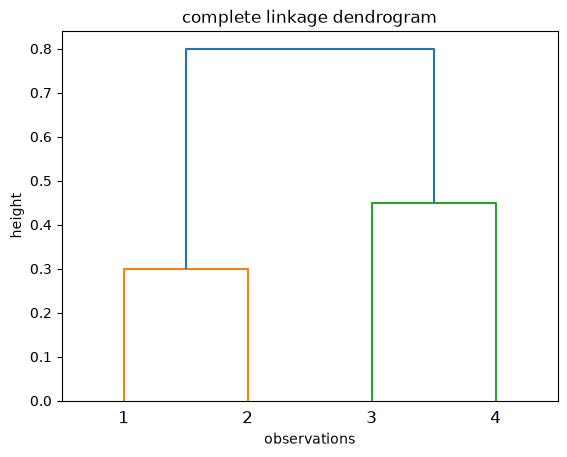

In [25]:
d = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

z = linkage(squareform(d), method = "complete")

dendrogram(z, labels = ["1", "2", "3", "4"])
plt.xlabel("observations")
plt.ylabel("height")
plt.title("complete linkage dendrogram")
plt.show()

### b.

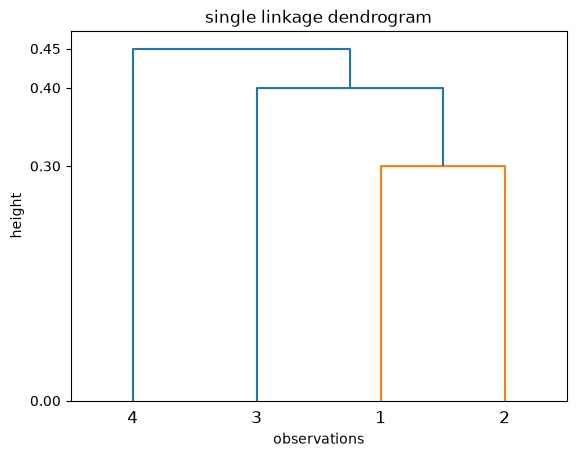

In [26]:
z_single = linkage(squareform(d), method = "single")

dendrogram(z_single, labels = ["1", "2", "3", "4"])
plt.yticks([0, 0.3, 0.4, 0.45])
plt.xlabel("observations")
plt.ylabel("height")
plt.title("single linkage dendrogram")
plt.show()

### c.

The two clusters are {1, 2} and {3, 4}.

### d.

The two clusters are {1, 2, 3} and {4}.

### e.

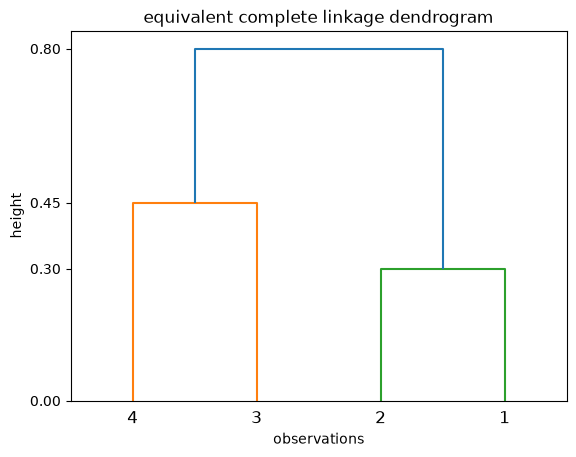

In [27]:
dendrogram(
    z,
    labels = ["1", "2", "3", "4"],
    count_sort = "descending"
)

plt.yticks([0, 0.3, 0.45, 0.8])
plt.xlabel("observations")
plt.ylabel("height")
plt.title("equivalent complete linkage dendrogram")
plt.show()